# IL-8 (CXCL8): infection-context LFC vs butyrate-dose LFC

**Extraction is identical to the co-infection correlation figure**
(`Epithelial_Coinfection_LFC_Correlation_ULTIMATE`): A06 log2FC/padj come from
`feat_df = analysis/causal_v6/full_feature_matrix.csv` via the exact `get_lfc_padj(gene, cond)`
(columns `lfc_Bt/Cd/Co`, `padj_Bt/Cd/Co`). A04 butyrate log2FC come from the DE tables.
Nothing is invented — every bar is read from a file.

Left group = **infection contexts** (Bt / Cd / Co vs Mock, from feat_df).
Right group = **butyrate only, by dose** (5/10 mM in Mock and in Cd, from A04 DE tables).
Goal: see whether butyrate-only moves IL-8 the way the infection contexts do.

Kernel: any pandas/matplotlib env. Run from the A04 notebooks dir (or set A06_PROJ/A04_PROJ).

In [1]:
import pandas as pd, numpy as np, os, re
from pathlib import Path
import matplotlib as mpl, matplotlib.pyplot as plt

A06 = Path(os.environ.get('A06_PROJ', str(Path.home()/'Projects_shared/epithelial_coinfection-model_WORKING')))
A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
FIG = A04/'results/figures'; FIG.mkdir(parents=True, exist_ok=True)
GENE='CXCL8'

mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'axes.linewidth':0.8,'axes.edgecolor':'#444','axes.spines.top':False,'axes.spines.right':False,
  'xtick.color':'#444','ytick.color':'#444','figure.dpi':140,'savefig.dpi':300,'savefig.bbox':'tight'})

## 1. A06 infection contexts — EXACT loader from the correlation figure (feat_df)

In [2]:
# same path + fallbacks as the ULTIMATE notebook
feat_path=None
for p in ['analysis/causal_v6/full_feature_matrix.csv',
          'analysis/causal_v4/full_feature_matrix.csv',
          'analysis/causal_v2/full_feature_matrix.csv']:
    if (A06/p).exists(): feat_path=A06/p; break
print('feat_df:', feat_path)
feat_df=pd.read_csv(feat_path, index_col='gene')
print('shape',feat_df.shape,'| lfc cols:',[x for x in feat_df.columns if x.startswith('lfc_')])

def get_lfc_padj(gene, condition):
    if gene not in feat_df.index: return 0.0, 1.0
    row=feat_df.loc[gene]
    return float(row.get(f'lfc_{condition}',0.0)), float(row.get(f'padj_{condition}',1.0))

rows=[]
for cond,label in [('Cd','Cd vs Mock'),('Co','Co-infection vs Mock'),('Bt','Bt vs Mock')]:
    lfc,padj=get_lfc_padj(GENE,cond)
    rows.append(dict(label=label,group='infection context',lfc=lfc,padj=padj))
print(f'\n{GENE} in infection contexts:')
for r in rows: print('  ',r['label'],'lfc=%.3f padj=%.2e'%(r['lfc'],r['padj']))

feat_df: /home/job37yv/Projects_shared/epithelial_coinfection-model_WORKING/analysis/causal_v6/full_feature_matrix.csv
shape (766, 43) | lfc cols: ['lfc_Bt', 'lfc_Cd', 'lfc_Co', 'lfc_Bt_vs_Cd', 'lfc_Co_vs_Cd']

CXCL8 in infection contexts:
   Cd vs Mock lfc=3.197 padj=3.14e-09
   Co-infection vs Mock lfc=0.877 padj=4.47e-01
   Bt vs Mock lfc=0.156 padj=9.79e-01


## 2. A04 butyrate-only, by dose — from the DE tables

In [3]:
def de_val(fname,gene):
    f=A04/'results/tables'/fname
    if not f.exists(): print('  MISSING',fname); return (np.nan,np.nan)
    d=pd.read_csv(f,index_col=0)
    for col in ['gene_name','symbol','Gene','gene']:
        if col in d.columns: d=d.set_index(col); break
    d.index=[re.sub(r'\..*','',str(i)) for i in d.index]
    if gene not in d.index: return (np.nan,np.nan)
    r=d.loc[gene]; return float(r.get('log2FoldChange',np.nan)), float(r.get('padj',np.nan))

# butyrate contrasts = the effect of butyrate itself (dose vs 0), in Mock and in Cd
A04_specs=[
  ('DE_Butyrate_5v0_Mock.csv', 'Butyrate 5mM (Mock)',  'butyrate only'),
  ('DE_Butyrate_10v0_Mock.csv','Butyrate 10mM (Mock)', 'butyrate only'),
  ('DE_Butyrate_5v0_Cd.csv',   'Butyrate 5mM (in Cd)', 'butyrate + infection'),
  ('DE_Butyrate_10v0_Cd.csv',  'Butyrate 10mM (in Cd)','butyrate + infection'),
]
for fn,label,grp in A04_specs:
    lfc,padj=de_val(fn,GENE)
    if not np.isnan(lfc): rows.append(dict(label=label,group=grp,lfc=lfc,padj=padj))
df=pd.DataFrame(rows)
print(f'\nAll {GENE} bars:'); print(df.round(3).to_string())


All CXCL8 bars:
                   label                 group    lfc   padj
0             Cd vs Mock     infection context  3.197  0.000
1   Co-infection vs Mock     infection context  0.877  0.447
2             Bt vs Mock     infection context  0.156  0.979
3    Butyrate 5mM (Mock)         butyrate only -0.922  0.080
4   Butyrate 10mM (Mock)         butyrate only -1.544  0.000
5   Butyrate 5mM (in Cd)  butyrate + infection -0.925  0.034
6  Butyrate 10mM (in Cd)  butyrate + infection -3.734  0.000


## 3. Plot — infection LFC vs butyrate LFC, p-value encoded

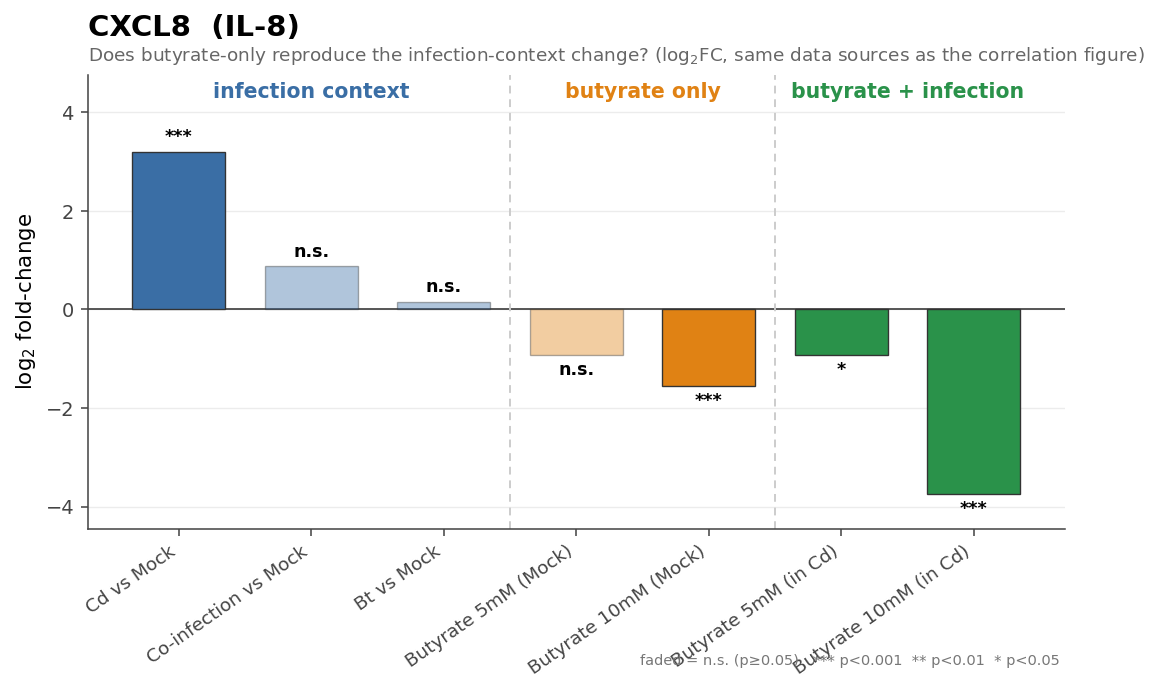

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/figures/CXCL8_infection_vs_butyrate.png


In [4]:
def stars(p):
    if pd.isna(p): return 'n.s.'
    return '***' if p<1e-3 else '**' if p<1e-2 else '*' if p<0.05 else 'n.s.'

group_order=['infection context','butyrate only','butyrate + infection']
gcol={'infection context':'#3a6ea5','butyrate only':'#e08214','butyrate + infection':'#2a924a'}
df=df[df.group.isin(group_order)].copy()
df['go']=df.group.map({g:i for i,g in enumerate(group_order)})
df=df.sort_values('go').reset_index(drop=True)

n=len(df); x=np.arange(n)
alphas=[1.0 if (not pd.isna(p) and p<0.05) else 0.40 for p in df.padj]
fig,ax=plt.subplots(figsize=(max(8,0.95*n+2),5.2))
bars=ax.bar(x,df.lfc,color=[gcol[g] for g in df.group],edgecolor='#333',lw=.7,width=.70,zorder=3)
for b,a in zip(bars,alphas): b.set_alpha(a)
for xi,(_,r) in zip(x,df.iterrows()):
    ax.text(xi,r.lfc+(0.12 if r.lfc>=0 else -0.12),stars(r.padj),
            ha='center',va='bottom' if r.lfc>=0 else 'top',fontsize=9,fontweight='bold')
ax.axhline(0,color='#444',lw=.9)
ylo,yhi=ax.get_ylim(); pad=(yhi-ylo)*0.16; ax.set_ylim(ylo-pad*0.3,yhi+pad)
for g in group_order:
    sub=df[df.group==g]
    if len(sub)==0: continue
    lo,hi=sub.index.min(),sub.index.max()
    if hi<n-1: ax.axvline(hi+0.5,color='#ccc',ls=(0,(4,3)),lw=1)
    ax.text((lo+hi)/2, ax.get_ylim()[1]*0.97, g, ha='center', va='top',
            fontsize=10.5, color=gcol[g], fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(df.label,rotation=35,ha='right',fontsize=9.5)
ax.set_ylabel('log$_2$ fold-change',fontsize=11)
ax.set_title('CXCL8  (IL-8)',fontsize=15,fontweight='bold',loc='left',pad=20)
ax.text(0,1.03,'Does butyrate-only reproduce the infection-context change? (log$_2$FC, same data sources as the correlation figure)',
        transform=ax.transAxes,fontsize=9.5,color='#666')
ax.grid(axis='y',color='#ececec',lw=.7,zorder=0)
ax.text(0.995,-0.30,'faded = n.s. (p≥0.05)   *** p<0.001  ** p<0.01  * p<0.05',
        transform=ax.transAxes,ha='right',fontsize=7.5,color='#777')
plt.tight_layout(); fig.savefig(FIG/'CXCL8_infection_vs_butyrate.png'); plt.show()
print('wrote',FIG/'CXCL8_infection_vs_butyrate.png')

## 4. Reading it
- **infection context** (blue): CXCL8 up with Cd; attenuated in Co (Bt present); Bt alone flat.
  These are the exact feat_df values behind the correlation figure (Cd/Co/Bt vs Mock).
- **butyrate only** (orange): butyrate in Mock — does the metabolite lower IL-8 with no infection?
- **butyrate + infection** (green): butyrate within Cd — the dose-dependent suppression.

The poster comparison: does butyrate-only (orange) push IL-8 in the same direction the commensal
does in co-infection (blue 'Co-infection vs Mock' being lower than 'Cd vs Mock')? If yes → butyrate
reproduces the commensal's anti-inflammatory effect on IL-8.

Swap gene: set GENE='HSPA5' (or CXCL1/CCL20/NFKB1) in cell 1 and re-run.